<a href="https://colab.research.google.com/github/lagavenkateswarlu/LG-Portfolio/blob/main/DIABETES_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

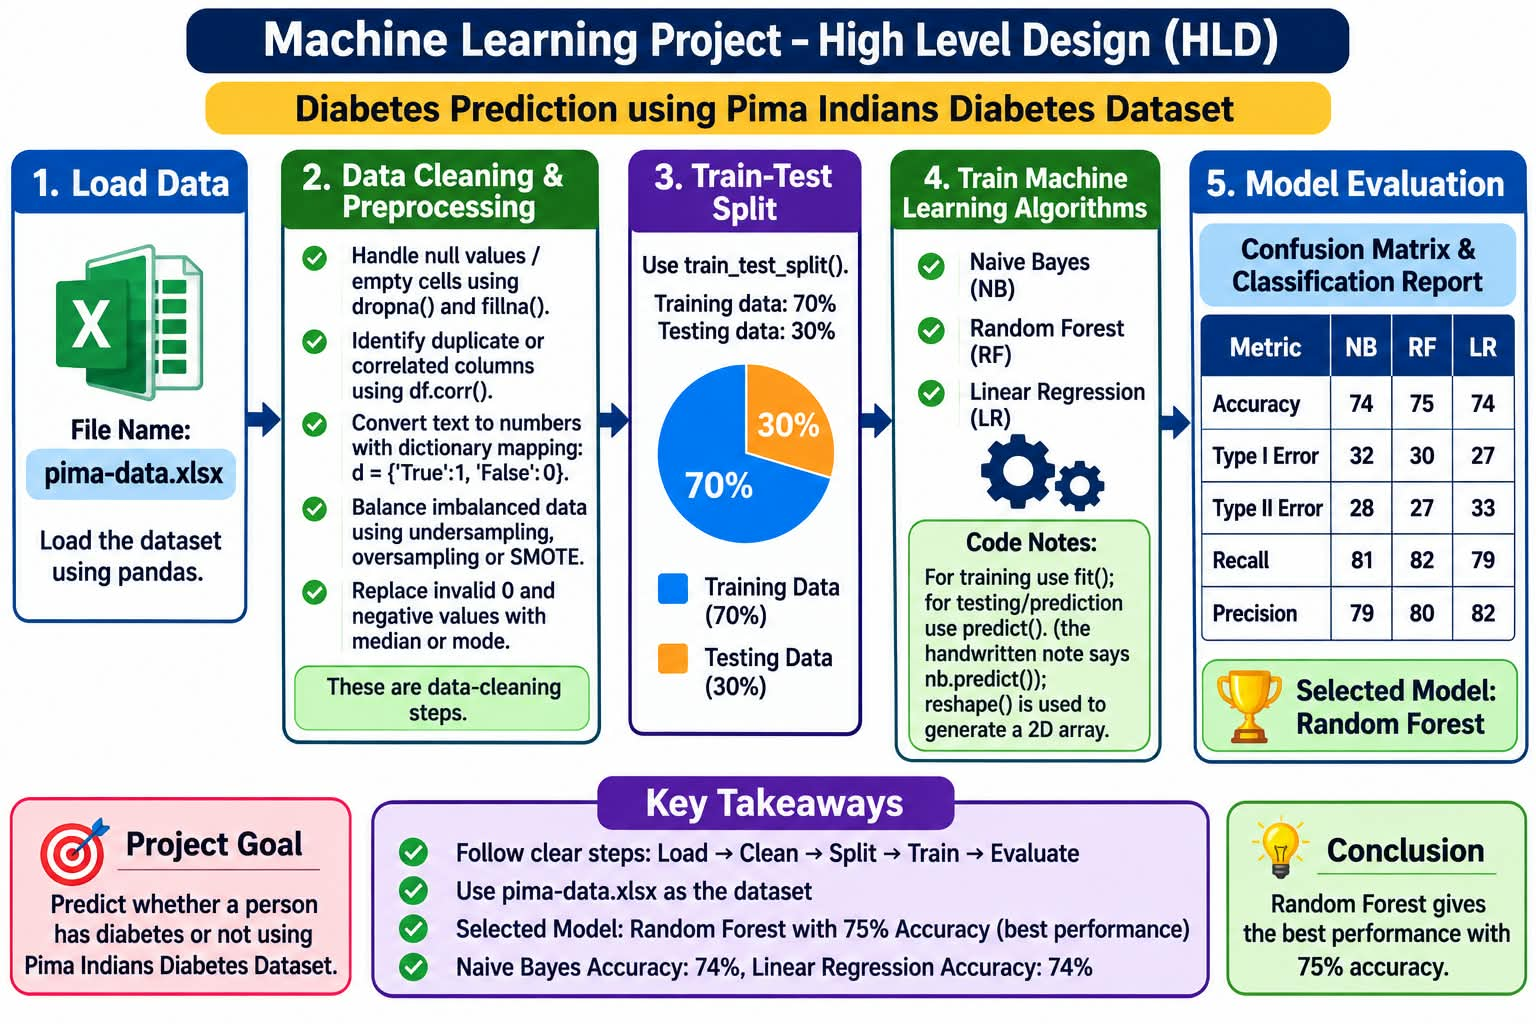

# ****IMPORT ALL LIBRARIES****

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics


%matplotlib inline
#THIS LINE SAYS THAT DISPLAY MATPLOTLIB PICTURES INLINE(NOT POP UP)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving pima-data.xlsx to pima-data.xlsx


# ****STEP.1 - LOAD THE DATA****

In [ ]:
df=pd.read_excel('pima-data.xlsx')

In [ ]:
df.shape #IT SHOWS THAT ROW AND COLUMN COUNT

(768, 11)

In [ ]:
df.head() # IT SHOWS FIRST FIVE ROWS DATA

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True


In [ ]:
df.tail()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
763,10,101,76,48,180,32.9,0.171,63,0,1.8912,False
764,2,122,70,27,0,36.8,0.340,27,0,1.0638,False
765,5,121,72,23,112,26.2,0.245,30,0,0.9062,False
766,1,126,60,0,0,30.1,0.349,47,1,0.0000,True
767,1,93,70,31,0,30.4,0.315,23,0,1.2214,False


In [ ]:
df.info()#check data information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_preg       768 non-null    int64  
 1   glucose_conc   768 non-null    int64  
 2   diastolic_bp   768 non-null    int64  
 3   thickness      768 non-null    int64  
 4   insulin        768 non-null    int64  
 5   bmi            768 non-null    float64
 6   diab_pred      768 non-null    float64
 7   age            768 non-null    int64  
 8   diabetes_orig  768 non-null    int64  
 9   skin           768 non-null    float64
 10  diabetes       768 non-null    bool   
dtypes: bool(1), float64(3), int64(7)
memory usage: 60.9 KB


In [ ]:
df.describe()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958,0.809136
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951,0.628517
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000,0.906200
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000,1.260800
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000,3.900600


# ****STEP.2 - CLEAN THE DATA****

### 1.CHECK IF THERE IS ANY NULL VALUES

In [ ]:
df.isnull().sum() # IT CHECKS IF ANY CELLS CONTAINING NULL VALUES OR NOT

,0
num_preg,0
glucose_conc,0
diastolic_bp,0
thickness,0
insulin,0
bmi,0
diab_pred,0
age,0
diabetes_orig,0
skin,0


In [ ]:
df.isnull().values.any() # IT CHECKS IF ANY CELLS CONTAINING NULL VALUES OR NOT

np.False_

### 2.CHECK IF THERE IS CORRELATED COLUMNS OR DUPLICATE COLUMNS
    ##### 1.first check how many columns are there in dataset -->11

In [ ]:
def plot_corr(df, size=11):
    corr = df.corr()
    fig, ax = plt.subplots(figsize=(size, size))
    ax.matshow(corr)
    plt.xticks(range(len(corr.columns)), corr.columns)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.show()
    plt.close(fig)

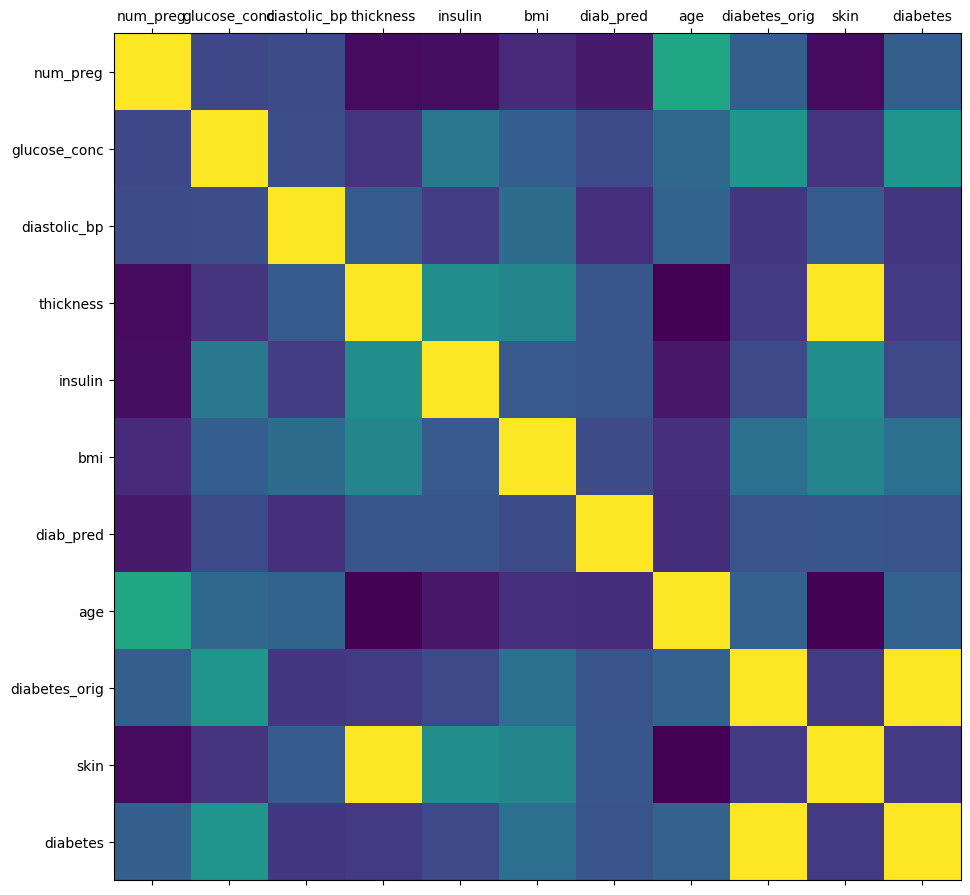

In [ ]:
plot_corr(df)

  ### 2.we are going to remove diabetes_orgin and thickness

In [ ]:
df.columns # NOW I AM CHECKING ALL COLUMNS

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'thickness', 'insulin',
       'bmi', 'diab_pred', 'age', 'diabetes_orig', 'skin', 'diabetes'],
      dtype='object')

In [ ]:
del df['diabetes_orig']
del df['thickness'] # I HAS DELETE THIS COLUMNS

In [ ]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True
1,1,85,66,0,26.6,0.351,31,1.1426,False
2,8,183,64,0,23.3,0.672,32,0.0000,True
3,1,89,66,94,28.1,0.167,21,0.9062,False
4,0,137,40,168,43.1,2.288,33,1.3790,True


In [ ]:
diabetes_map = {True:1,False:0}
df['diabetes']=df['diabetes'].map(diabetes_map) # BY USING DICTIONARY I CONVERTED TEXT TO NUMBERS

In [ ]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1


  ### 4.balance the imbalance data
  ### acurately predicting rare events its not easy

# Since we are predicting diabetes true or false,
# we have to ensure our training data has equal proportion
# of training sets with diabetes and without diabetes.
# If we have too many rows diabetes or vice versa,
# then algorithm might not work well.
# Let's see how much % of rows are diabetes and
# how much % is not diabetes.

In [ ]:
# Check true or false ratios.
#we need the ensure that portion should be portion balanced (50-50)
#diabetes and non diabetes or atleast close enough to proceed.


num_true = len(df.loc[df['diabetes'] == True])
num_false = len(df.loc[df['diabetes'] == False])

print('true = ', (num_true / (num_true + num_false)) * 100)
print('false = ', (num_false / (num_true + num_false)) * 100)

true =  34.89583333333333
false =  65.10416666666666


### 5.check there is zeros are there or not

In [ ]:
print('# rows in dataframe {0}'.format(len(df)))
print('# rows missing glucose_conc : {0}'.format(len(df.loc[df['glucose_conc'] == 0])))
print('# rows missing diastolic_bp : {0}'.format(len(df.loc[df['diastolic_bp'] == 0])))
print('# rows missing thickness : {0}'.format(len(df.loc[df['skin'] == 0])))
print('# rows missing insulin : {0}'.format(len(df.loc[df['insulin'] == 0])))
print('# rows missing bmi : {0}'.format(len(df.loc[df['bmi'] == 0])))
print('# rows missing diab_pred : {0}'.format(len(df.loc[df['diab_pred'] == 0])))
print('# rows missing age : {0}'.format(len(df.loc[df['age'] == 0])))

# rows in dataframe 768
# rows missing glucose_conc : 5
# rows missing diastolic_bp : 35
# rows missing thickness : 227
# rows missing insulin : 374
# rows missing bmi : 11
# rows missing diab_pred : 0
# rows missing age : 0


# ****STEP.3 - TRAIN TEST SPLIT THE DATA****

In [ ]:
from sklearn.model_selection import train_test_split

feature_col_names = ['num_preg', 'glucose_conc', 'diastolic_bp',
                      'insulin', 'bmi', 'diab_pred', 'age','skin']

predicted_class_names = ['diabetes']

X = df[feature_col_names].values
y = df[predicted_class_names].values

split_test_size = 0.30

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=split_test_size,
    random_state=42
)

###  convert zeros to mean,median,mode values

In [ ]:
from sklearn.impute import SimpleImputer

fill_0 = SimpleImputer(missing_values=0, strategy='mean')

x_train = fill_0.fit_transform(x_train)

x_test = fill_0.transform(x_test)

In [ ]:
x_train[0:10] # checking any 0 are there

array([[1.00000000e+00, 9.50000000e+01, 6.00000000e+01, 5.80000000e+01,
        2.39000000e+01, 2.60000000e-01, 2.20000000e+01, 7.09200000e-01],
       [5.00000000e+00, 1.05000000e+02, 7.20000000e+01, 3.25000000e+02,
        3.69000000e+01, 1.59000000e-01, 2.80000000e+01, 1.14260000e+00],
       [4.34056399e+00, 1.35000000e+02, 6.80000000e+01, 2.50000000e+02,
        4.23000000e+01, 3.65000000e-01, 2.40000000e+01, 1.65480000e+00],
       [4.00000000e+00, 1.31000000e+02, 6.80000000e+01, 1.66000000e+02,
        3.31000000e+01, 1.60000000e-01, 2.80000000e+01, 8.27400000e-01],
       [1.00000000e+00, 1.03000000e+02, 3.00000000e+01, 8.30000000e+01,
        4.33000000e+01, 1.83000000e-01, 3.30000000e+01, 1.49720000e+00],
       [2.00000000e+00, 8.20000000e+01, 5.20000000e+01, 1.15000000e+02,
        2.85000000e+01, 1.69900000e+00, 2.50000000e+01, 8.66800000e-01],
       [3.00000000e+00, 1.28000000e+02, 7.80000000e+01, 1.55333333e+02,
        2.11000000e+01, 2.68000000e-01, 5.50000000e+01, 1.

# ****STEP.4 - TRAIN THE MODEL****

## THIS IS NAIVE BAYES ALGORITHM

In [ ]:
from sklearn.naive_bayes import GaussianNB

# create gaussian naive bayes model object and train it with data
nb_model = GaussianNB()

nb_model.fit(x_train, y_train.ravel())

GaussianNB()

In [ ]:
#lets test the algorithm's accuracy with training data itself
nb_predict_train = nb_model.predict(x_train)

# import the performance metrics library
from sklearn import metrics

# accuracy
print('accuracy : {0:.4f}'.format(metrics.accuracy_score(y_train,
                                                        nb_predict_train)))

accuracy : 0.7542


# ****STEP.5 - TEST THE MODEL****

In [ ]:
nb_predict_test = nb_model.predict(x_test)
from sklearn import metrics

print('accuracy : {0:.4f}'.format(
    metrics.accuracy_score(y_test, nb_predict_test)
))

accuracy : 0.7403


# ****STEP.6 - ANALYZE THE MODEL ACCURACY WITH CONFUSION MATRIX****

####****FIRST WE NEED TO UNDERSTAND CONFUSION MATRIX****

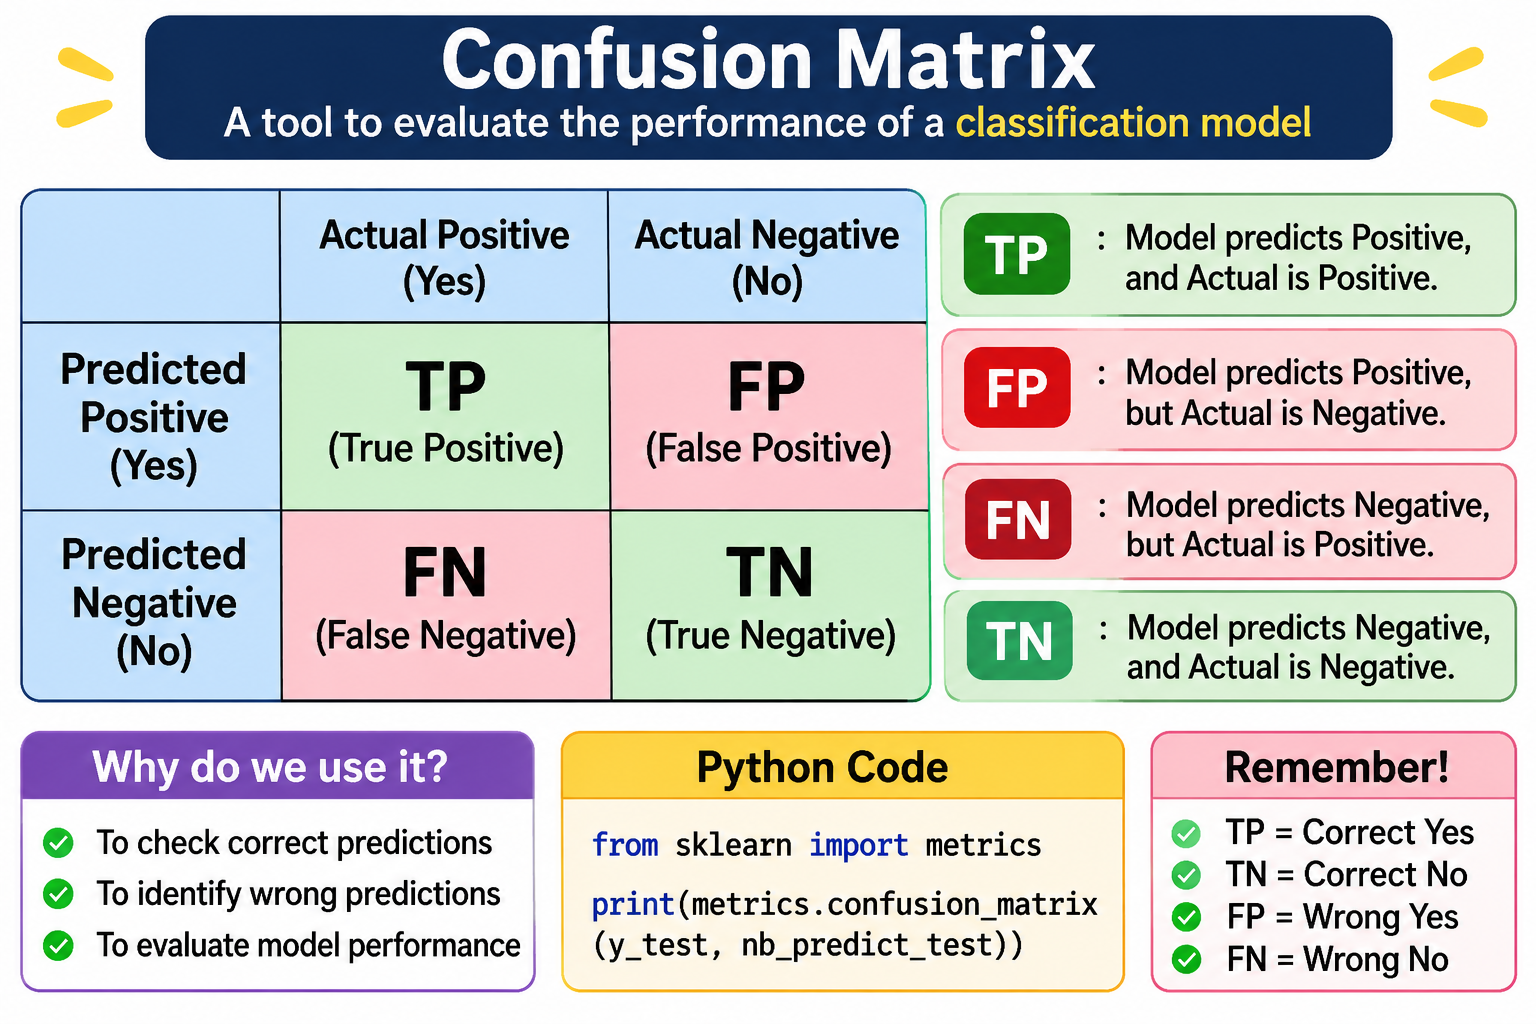

In [ ]:
from sklearn import metrics
print(metrics.confusion_matrix(y_test, nb_predict_test))

[[119  32]
 [ 28  52]]


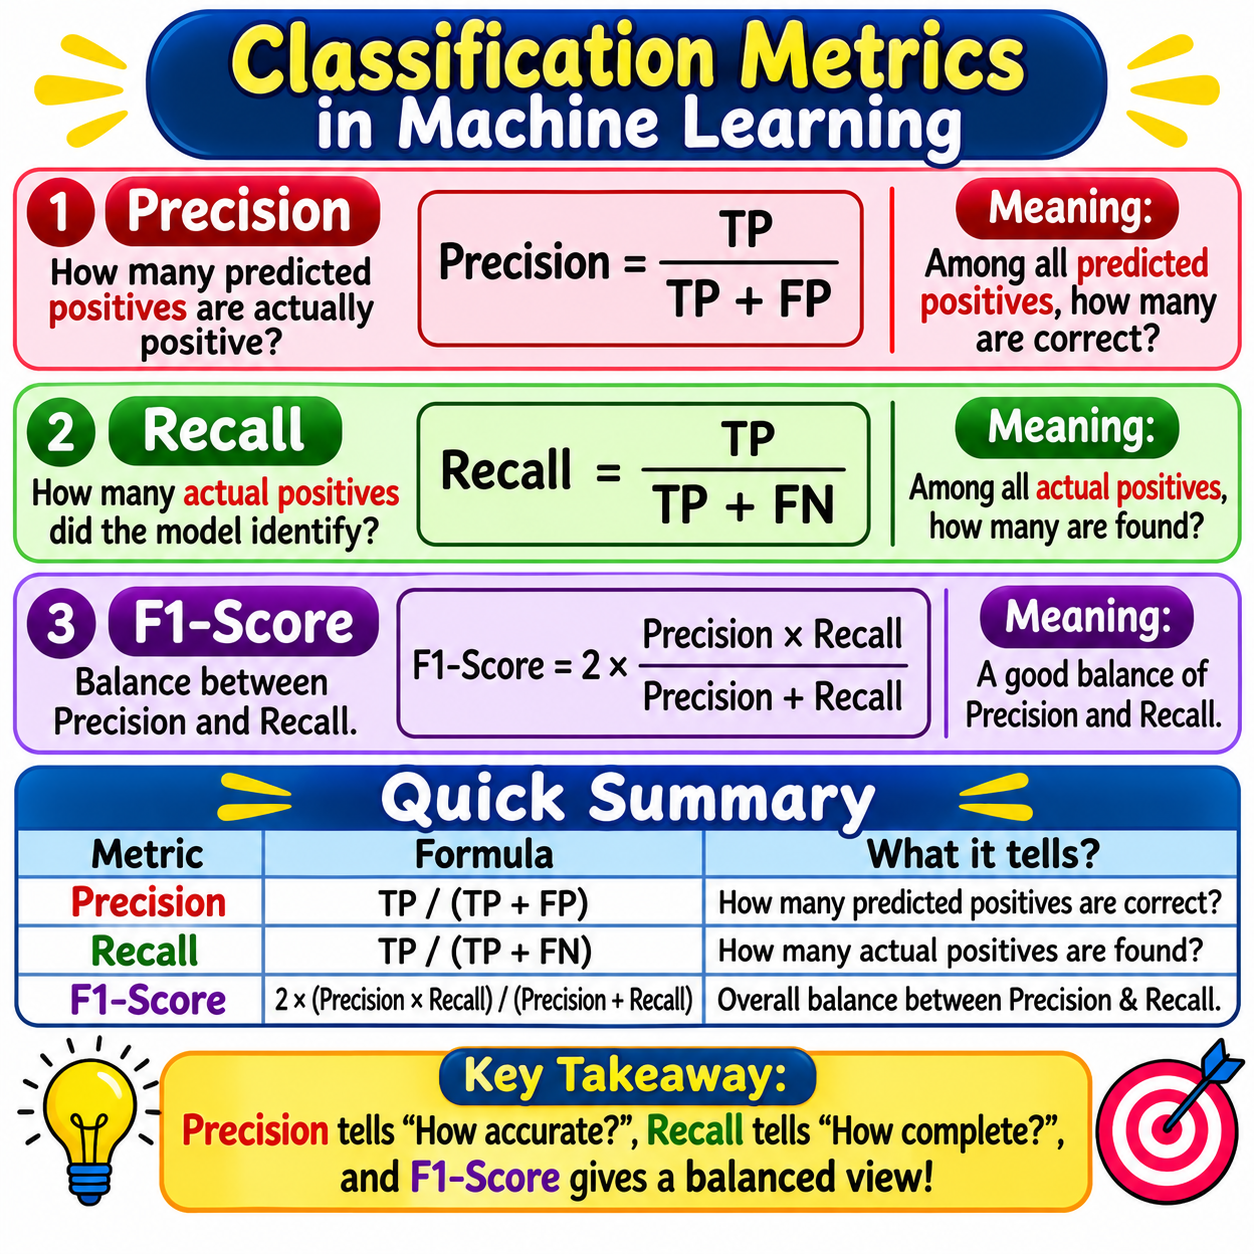

In [ ]:
print(metrics.classification_report(y_test, nb_predict_test))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80       151
           1       0.62      0.65      0.63        80

    accuracy                           0.74       231
   macro avg       0.71      0.72      0.72       231
weighted avg       0.74      0.74      0.74       231



# ****Final observations of navie bayes algorithm acuracy 74%,recall 81%****
###****TYPE 2 ERROR VALUES SHOULD BE LESS COMPARED TO TYPE 1 ERROR****

In [ ]:
# Performance improvement options

# 1. Adjust hyperparameters to current algorithm
# 2. Unfortunately, Naive Bayes doesn't have that parameter
# 3. Another option: Get more data or improve data
# 4. Another option: Improve training [will do later]
# 5. Another option: Switch algorithm


# ****NOW I AM TRY WITH RANDOM FOREST****

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

# Train Random Forest model
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(x_train, y_train.ravel())

# Predict on test data
rf_predict_test = rf_model.predict(x_test)

# Accuracy
print('accuracy : {0:.4f}'.format(
    metrics.accuracy_score(y_test, rf_predict_test)
))

accuracy : 0.7532


## lets check cofusion matrics and classification report for random forest


In [ ]:
print(metrics.confusion_matrix(y_test, rf_predict_test))
print('')

print('classification report')
print(metrics.classification_report(y_test, rf_predict_test))


[[121  30]
 [ 27  53]]

classification report
              precision    recall  f1-score   support

           0       0.82      0.80      0.81       151
           1       0.64      0.66      0.65        80

    accuracy                           0.75       231
   macro avg       0.73      0.73      0.73       231
weighted avg       0.76      0.75      0.75       231



# ****NOW I AM TRY WITH LOGISTIC REGRESSION AND CHECKING ACURACY CONFUSION MATRICS AND CLASIFICATION REPORT****

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# Logistic Regression Model
lr_model = LogisticRegression(C=0.2, random_state=42)#C HYPERPARAMETER

lr_model.fit(x_train, y_train.ravel())

lr_predict_test = lr_model.predict(x_test)

# Training Metrics
print('accuracy: {0:.4f}'.format(
    metrics.accuracy_score(y_test, lr_predict_test)
))

print('')

print(metrics.confusion_matrix(y_test, lr_predict_test))

print('')

print('classification report')

print(metrics.classification_report(
    y_test,
    lr_predict_test
))

accuracy: 0.7403

[[124  27]
 [ 33  47]]

classification report
              precision    recall  f1-score   support

           0       0.79      0.82      0.81       151
           1       0.64      0.59      0.61        80

    accuracy                           0.74       231
   macro avg       0.71      0.70      0.71       231
weighted avg       0.74      0.74      0.74       231



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#****Final Conclusion:****

#**We recommend the Random Forest algorithm for this project because it achieved an accuracy of 75% and a recall value of 82%, which are higher than those of the other two algorithms, namely Naive Bayes and Logistic Regression. Therefore, Random Forest provides the best overall performance for this dataset and is selected as the final model.**